# 04 - Weekly Booking Forecast - H1c

**Input:** `data/processed/salon_clean.csv`

Simple exponential smoothing (SES) vs a naive baseline (repeat last week's count),
evaluated on the 13 holdout weeks. Forecasts are rolling one-step-ahead: each
holdout week is predicted using only the weeks before it.

In [7]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from scenarios import TRAIN_FRAC

s = pd.read_csv("../data/processed/salon_clean.csv", parse_dates=["appt_dt"])

# All bookings count toward demand (incl. cancellations and the 1:00 record)
WEEKS = range(int(s["week_index"].max()) + 1)
weekly = s.groupby("week_index").size().reindex(WEEKS, fill_value=0).astype(float)
n_train = int(round(len(weekly) * TRAIN_FRAC))
train, test = weekly.iloc[:n_train], weekly.iloc[n_train:]

print("Weeks:", len(weekly), "| train:", len(train), "| test:", len(test))
print("Total bookings:", int(weekly.sum()))                  # expect 186
print("Zero-booking weeks:", int((weekly == 0).sum()))
print(weekly.describe().round(2))

Weeks: 44 | train: 31 | test: 13
Total bookings: 186
Zero-booking weeks: 3
count    44.00
mean      4.23
std       2.65
min       0.00
25%       1.75
50%       4.50
75%       6.00
max       9.00
dtype: float64


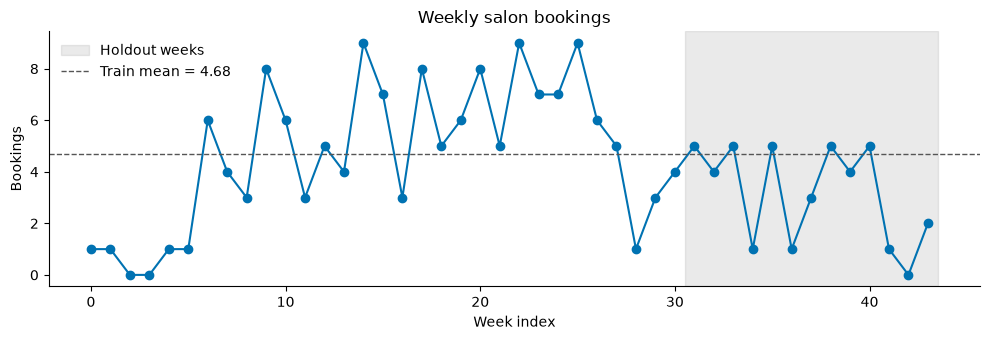

Train trend slope: 0.146 bookings/week, p = 0.007


In [8]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(weekly.index, weekly.values, marker="o", color="#0072B2")
ax.axvspan(n_train - 0.5, len(weekly) - 0.5, color="#999999", alpha=0.2, label="Holdout weeks")
ax.axhline(train.mean(), ls="--", color="#555555", lw=1, label=f"Train mean = {train.mean():.2f}")
ax.set(title="Weekly salon bookings", xlabel="Week index", ylabel="Bookings")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

# Simple trend check: is there a linear trend in the training weeks?
slope = stats.linregress(train.index, train.values)
print(f"Train trend slope: {slope.slope:.3f} bookings/week, p = {slope.pvalue:.3f}")

In [9]:
# Robustness: is the trend just the low start-up weeks?
trim = train.iloc[6:]
slope_trim = stats.linregress(trim.index, trim.values)
print(f"Trend excluding weeks 0-5: {slope_trim.slope:.3f} bookings/week, p = {slope_trim.pvalue:.3f}")
print(f"Train mean: {train.mean():.2f} | Holdout mean: {test.mean():.2f}")

Trend excluding weeks 0-5: -0.008 bookings/week, p = 0.893
Train mean: 4.68 | Holdout mean: 3.15


In [10]:
ses_pred, naive_pred, alphas = [], [], []
for i in range(n_train, len(weekly)):
    hist = weekly.iloc[:i]
    fit = SimpleExpSmoothing(hist.values, initialization_method="estimated").fit()
    ses_pred.append(fit.forecast(1)[0])
    naive_pred.append(hist.iloc[-1])
    alphas.append(fit.params["smoothing_level"])
ses_pred, naive_pred = np.array(ses_pred), np.array(naive_pred)
y = test.values

def metrics(y, p):
    err = y - p
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err**2)),
            "WAPE": np.abs(err).sum() / y.sum()}

res = pd.DataFrame({"SES": metrics(y, ses_pred), "Naive": metrics(y, naive_pred)}).T
print(res.round(3))
print(f"\nSES alpha range across refits: {min(alphas):.3f} to {max(alphas):.3f}")

# H1c: paired one-sided Wilcoxon on absolute errors
ae_ses, ae_naive = np.abs(y - ses_pred), np.abs(y - naive_pred)
w = stats.wilcoxon(ae_ses, ae_naive, alternative="less", zero_method="wilcox")
print(f"Wilcoxon (SES < naive): W = {w.statistic:.1f}, p = {w.pvalue:.4f}")
print("Weeks with tied errors (dropped by test):", int((ae_ses == ae_naive).sum()))
print(f"MAE improvement: {res.loc['Naive','MAE'] - res.loc['SES','MAE']:.2f} bookings/week "
      f"({1 - res.loc['SES','MAE']/res.loc['Naive','MAE']:.0%})")

         MAE   RMSE   WAPE
SES    1.613  2.011  0.512
Naive  2.154  2.512  0.683

SES alpha range across refits: 0.361 to 0.421
Wilcoxon (SES < naive): W = 20.0, p = 0.0402
Weeks with tied errors (dropped by test): 0
MAE improvement: 0.54 bookings/week (25%)


Differences (SES - naive): [ 0.24 -0.71 -0.17 -0.49 -2.1  -1.14 -1.76  0.14 -0.67  0.21 -0.75  2.06
 -1.88]
Median: -0.67 | Mean: -0.54 | Skew: 0.68


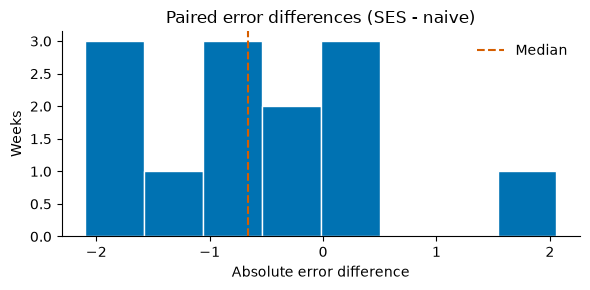

In [11]:
# C4 assumption: Wilcoxon signed-rank expects some symmetric differences
diff = ae_ses - ae_naive
print("Differences (SES - naive):", np.round(diff, 2))
print(f"Median: {np.median(diff):.2f} | Mean: {diff.mean():.2f} | Skew: {stats.skew(diff):.2f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(diff, bins=8, color="#0072B2", edgecolor="white")
ax.axvline(np.median(diff), color="#D55E00", ls="--", label="Median")
ax.set(title="Paired error differences (SES - naive)", xlabel="Absolute error difference", ylabel="Weeks")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

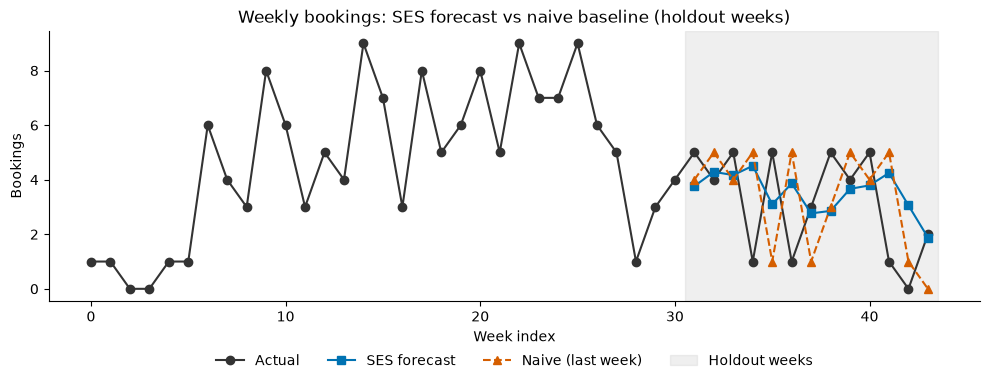

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly.index, weekly.values, marker="o", color="#333333", label="Actual")
ax.plot(test.index, ses_pred, marker="s", color="#0072B2", label="SES forecast")
ax.plot(test.index, naive_pred, marker="^", ls="--", color="#D55E00", label="Naive (last week)")
ax.axvspan(n_train - 0.5, len(weekly) - 0.5, color="#999999", alpha=0.15, label="Holdout weeks")
ax.set(title="Weekly bookings: SES forecast vs naive baseline (holdout weeks)",
       xlabel="Week index", ylabel="Bookings")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../outputs/figures/fig04_forecast.png", dpi=200)
plt.show()

## Findings
- SES MAE 1.61 vs naive 2.15 (25% lower); RMSE 2.01 vs 2.51; WAPE 51% vs 68%

- H1c supported: one-sided Wilcoxon on paired absolute errors, p = 0.040; SES better in 9 of 13 weeks

- Training trend (p = 0.007) disappears once start-up weeks 0-5 excluded (p = 0.893), so a no-trend model (SES) was appropriate
- Holdout mean (3.15) below training mean (4.68): SES adapts to level changes

- Error differences are roughly symmetric (skew 0.68), satisfying the Wilcoxon assumption

- Weekly demand is stable enough to price against, but too noisy for staffing on a weekly basis